# 08逻辑回归：对数几率与正则化
04-06已经给出结论：模型是 sigmoid + 线性得分，损失是交叉熵，梯度是 `(1/n) X^T (p - y)`。

08 要做的是把这些结论**从假设变成推导**，回答三个“为什么”：

1. 为什么偏偏是 Sigmoid，而不是别的 S 形函数？
2. 为什么偏偏是交叉熵，而不是 MSE？
3. 为什么梯度形式这么干净？

## 起点：几率（odds）与对数几率（log-odds）
概率 `p` 的取值范围是 0 到 1，两端被卡死，不适合直接用线性函数拟合。

先做一步变换，定义**几率（odds）**：

$$
\\text{odds} = \\frac{p}{1 - p}
$$

含义是“发生与不发生的机会之比”。`p = 0.5` 时 odds = 1；`p` 趋近 1 时 odds 趋于正无穷；`p` 趋近 0 时 odds 趋于 0。取值范围是 0 到正无穷，**下界被打开了，但上界还封着**。

再取自然对数，得到**对数几率（log-odds，也叫 logit）**：

$$
\\text{logit}(p) = \\ln \\frac{p}{1 - p}
$$

此时取值范围变成整个实数轴，从负无穷到正无穷。这个空间里，线性函数终于可以自由取值了。

于是做一个自然假设：**让线性得分去拟合对数几率**。

$$
z = w^T x + b = \\ln \\frac{p}{1 - p}
$$

这就是逻辑回归的模型假设。所谓“逻辑回归”，回归的其实是这个对数几率，不是概率本身。

### 反解出 Sigmoid（关键一步）

从上面的式子解出 `p`。先两边取指数：

$$
e^{z} = \\frac{p}{1 - p}
$$

两边乘 `(1 - p)`：

$$
e^{z} - e^{z} p = p
$$

把含 `p` 的项移到一起：

$$
e^{z} = p(1 + e^{z})
$$

两边除以 `(1 + e^z)`：

$$
p = \\frac{e^{z}}{1 + e^{z}}
$$

分子分母同除 `e^z`：

$$
p = \\frac{1}{1 + e^{-z}}
$$

这就是 Sigmoid。

**结论**：Sigmoid 不是“随手挑的一个把数值压到 0~1 的函数”，而是“假设对数几率是线性的”这一前提的**必然结果**。这解释了 Day4 里那个悬而未决的问题。

用统计术语说：逻辑回归是**广义线性模型（GLM）**，链接函数是 logit，分布假设是伯努利分布。

## 概率视角：伯努利分布与似然
把标签看成伯努利随机变量，`p` 是取 1 的概率：

$$
P(y = 1 \\mid x) = p
$$

$$
P(y = 0 \\mid x) = 1 - p
$$

两种情况可以合并成一条式子（这是后续推导的基石）：

$$
P(y \\mid x) = p^{y} (1 - p)^{1 - y}
$$

验证一下：`y = 1` 时是 `p`，`y = 0` 时是 `1 - p`，正确。

### 似然函数

假设 n 个样本独立同分布，整个数据集出现的联合概率（似然）是连乘：

$$
L(w, b) = \\prod\_{i=1}^{n} p_i^{y_i} (1 - p_i)^{1 - y_i}
$$

其中 `p_i` 是第 i 个样本被预测为正类的概率，由 sigmoid 算出。

连乘在数值上极易下溢（几百个 0~1 的数相乘立刻变成 0），也不方便求导。取对数把连乘变连加：

$$
\\ln L(w, b) = \\sum\_{i=1}^{n} \\left[ y_i \\ln p_i + (1 - y_i) \\ln (1 - p_i) \\right]
$$

## 极大似然估计 = 最小化交叉熵
极大似然估计（MLE）的思路是：**选一组参数，让已经观测到的这批数据出现的概率最大**。也就是最大化上面的对数似然。

加负号，最大化变最小化：

$$
\\text{NLL} = -\\sum\_{i=1}^{n} \\left[ y_i \\ln p_i + (1 - y_i) \\ln (1 - p_i) \\right]
$$

再除以 n 取平均，正好就是 Day5 的交叉熵损失：

$$
J(w, b) = -\\frac{1}{n} \\sum\_{i=1}^{n} \\left[ y_i \\ln p_i + (1 - y_i) \\ln (1 - p_i) \\right]
$$

**结论**：交叉熵不是“分类任务约定俗成的损失”，它是伯努利分布下极大似然估计的负对数似然。这也顺带回答了 Day5 的问题——MSE 对应的是高斯噪声假设，用在 0/1 标签上等于假设错了分布，所以不合理。

## Sigmoid 的导数（先备好工具）
设：

$$
\\sigma(z) = \\frac{1}{1 + e^{-z}}
$$

写成幂次形式方便求导：

$$
\\sigma(z) = (1 + e^{-z})^{-1}
$$

用链式法则，外层是 `u^{-1}`，内层是 `1 + e^{-z}`：

$$
\\sigma'(z) = -1 \\cdot (1 + e^{-z})^{-2} \\cdot (-e^{-z})
$$

负负得正，整理：

$$
\\sigma'(z) = \\frac{e^{-z}}{(1 + e^{-z})^{2}}
$$

把它拆成两个因子的乘积：

$$
\\sigma'(z) = \\frac{1}{1 + e^{-z}} \\cdot \\frac{e^{-z}}{1 + e^{-z}}
$$

第一项就是 `σ(z)`；第二项注意到 `1 - σ(z)`：

$$
1 - \\sigma(z) = 1 - \\frac{1}{1 + e^{-z}} = \\frac{e^{-z}}{1 + e^{-z}}
$$

所以得到一个非常漂亮的结果：

$$
\\sigma'(z) = \\sigma(z)\\left(1 - \\sigma(z)\\right)
$$

用概率符号写就是：

$$
\\frac{\\partial p}{\\partial z} = p(1 - p)
$$

这个性质是后面梯度能化简的根本原因。

## 逐链求导：从损失到权重
现在完整走一遍链式法则。单个样本的损失为：

$$
\\ell = -\\left[ y \\ln p + (1 - y) \\ln (1 - p) \\right]
$$

### 第一步：损失对概率求导

对 `p` 求导，`ln p` 的导数是 `1/p`，`ln(1 - p)` 的导数是 `-1/(1 - p)`：

$$
\\frac{\\partial \\ell}{\\partial p} = -\\frac{y}{p} + \\frac{1 - y}{1 - p}
$$

### 第二步：概率对得分求导

用 8.4 的结论：

$$
\\frac{\\partial p}{\\partial z} = p(1 - p)
$$

### 第三步：两者相乘

$$
\\frac{\\partial \\ell}{\\partial z} = \\left( -\\frac{y}{p} + \\frac{1 - y}{1 - p} \\right) \\cdot p(1 - p)
$$

把 `p(1 - p)` 分别乘进括号：

$$
\\frac{\\partial \\ell}{\\partial z} = -y(1 - p) + (1 - y)p
$$

展开：

$$
= -y + yp + p - yp
$$

`yp` 与 `-yp` 抵消：

$$
\\frac{\\partial \\ell}{\\partial z} = p - y
$$

**这一步就是全部魔法所在**。`p(1 - p)` 这个复杂因子被完美抵消，只剩下“预测概率减真实标签”这个极其直观的量：预测高了就产生正梯度往回压，预测低了就产生负梯度往上抬。

### 第四步：得分对参数求导

$$
z = w^T x + b
$$

$$
\\frac{\\partial z}{\\partial w} = x
$$

$$
\\frac{\\partial z}{\\partial b} = 1
$$

### 第五步：汇总

单样本：

$$
\\frac{\\partial \\ell}{\\partial w} = (p - y), x
$$

$$
\\frac{\\partial \\ell}{\\partial b} = p - y
$$

对 n 个样本取平均，写成矩阵形式（`X` 是 n 行 d 列，`p`、`y` 是 n 维列向量）：

$$
\\frac{\\partial J}{\\partial w} = \\frac{1}{n} X^{T}(p - y)
$$

$$
\\frac{\\partial J}{\\partial b} = \\frac{1}{n} \\sum\_{i=1}^{n}(p_i - y_i)
$$

与 Day5 给的公式完全一致，但这次每一步都有来源。这也解释了 Day5 里提到的“和线性回归梯度形式一样”的巧合：本质是**指数族分布 + 对应链接函数**的通用结果，不是巧合。

## 凸性：为什么梯度下降一定收敛
判断一个函数是否凸，看二阶导（高维是 Hessian 矩阵）是否半正定。

单样本损失对 `z` 的二阶导：

$$
\\frac{\\partial^{2} \\ell}{\\partial z^{2}} = \\frac{\\partial (p - y)}{\\partial z} = p(1 - p)
$$

因为 `p` 在 0 到 1 之间，所以 `p(1 - p)` 恒大于等于 0，单个样本关于 `z` 是凸的。

写成整个参数的 Hessian（`S` 是对角矩阵，对角元为 `p_i(1 - p_i)`）：

$$
H = \\frac{1}{n} X^{T} S X
$$

对任意非零向量 `v`，有：

$$
v^{T} H v = \\frac{1}{n} \\sum\_{i=1}^{n} p_i(1 - p_i)\\left(x_i^{T} v\\right)^{2} \\geq 0
$$

每一项都是非负的平方乘非负系数，所以 Hessian 半正定，**损失函数是凸函数，局部最优就是全局最优**。

实测（`make_moons` 数据，手写解出的参数处）：

```
Hessian eigenvalues: [0.04981 0.10365]   all >= 0 : True
```

两个特征值都为正，验证了凸性。

对比一下 MSE + Sigmoid：

$$
L\_{\\text{MSE}} = (y - p)^{2}
$$

它对 `z` 的二阶导会出现 `p(1 - p)` 乘以一个可正可负的项，整体不再保证非负，函数非凸，存在多个局部极小，这就是 Day5 说“MSE 不能用于分类”的数学原因。

## 正则化：为什么需要、怎么加
### 为什么会过拟合

如果数据**线性可分**，交叉熵损失可以被无限压低：只要把 `w` 的范数不断放大，sigmoid 就会越来越陡，所有样本的预测概率都逼近 0 或 1，损失趋近 0。但这样得到的模型对噪声极度敏感，方差巨大。

实测（`class_sep=5` 的近可分数据）：

```
C=0.01   ||w|| = 0.539
C=100    ||w|| = 0.958
C=1e+06  ||w|| = 0.959
```

可以看到强正则（C 很小）把权重压到了 0.539，而无正则时稳定在 0.96 左右。正则化就是在“拟合训练数据”和“参数别太放肆”之间做权衡。

### L2 正则（岭回归式）

在损失后加参数平方项：

$$
J\_{L2}(w, b) = J(w, b) + \\frac{\\lambda}{2}|w|^{2}
$$

梯度变成：

$$
\\frac{\\partial J\_{L2}}{\\partial w} = \\frac{1}{n} X^{T}(p - y) + \\lambda w
$$

更新时多了一项 `- λw`，等价于每一轮都把权重按比例往 0 缩一点，所以 L2 也叫**权重衰减（weight decay）**。

效果：权重整体变小、更平滑，能缓解多重共线性，但不会把某个权重精确压到 0。

注意：正则项**只作用于 `w`，不加在 `b` 上**。偏置控制整体偏移，惩罚它没有意义。

### L1 正则（Lasso 式）

$$
J\_{L1}(w, b) = J(w, b) + \\lambda |w|\_{1}
$$

$$
|w|*{1} = \\sum*{j=1}^{d}|w_j|
$$

L1 的梯度是符号函数，几何上约束区域是菱形，最优点容易落在坐标轴上，因此会**产生稀疏解**——一部分权重精确等于 0，天然具备特征选择能力。

### ElasticNet

$$
J(w, b) = J(w, b) + \\lambda_1 |w|\_{1} + \\frac{\\lambda_2}{2}|w|^{2}
$$

兼顾稀疏与稳定，适合特征高度相关且数量很多的场景。

### L1 与 L2 对比

| 项目 | L2（Ridge） | L1（Lasso） |
| --- | --- | --- |
| 正则项 | 权重平方和 | 权重绝对值之和 |
| 权重效果 | 整体收缩，不会到 0 | 部分权重精确为 0 |
| 特征选择 | 无 | 有 |
| 相关特征 | 权重分摊、较稳定 | 随机挑一个留下 |
| 适用 | 特征都有用、存在共线性 | 特征多、大量冗余 |

### sklearn 里 `C` 与 `λ` 的换算（重要易错点）

sklearn 的 `LogisticRegression` 不直接接受 `λ`，而是用 `C`：

$$
\\text{目标} = \\frac{1}{2}|w|^{2} + C \\sum\_{i=1}^{n} \\ell_i
$$

两边同除 `C × n`：

$$
\\text{目标} = \\frac{1}{2Cn}|w|^{2} + \\frac{1}{n}\\sum\_{i=1}^{n}\\ell_i
$$

对照 `λ/2 · ||w||^2`，得到：

$$
\\lambda = \\frac{1}{C \\cdot n}
$$

所以：

- **`C` 越小，`λ` 越大，正则越强**（这一点和“参数越大越强”的直觉相反，是高频踩坑点）；
- `C = 1` 是默认值；
- `C` 取极大（如 1e6）近似无正则。

实测验证：n = 280，取 `C = 1`，则 `λ = 1/280 ≈ 0.003571`。手写梯度下降解出的权重与 sklearn 的 lbfgs 解最大差异仅 0.00046，说明换算关系正确。

## 8.8 多分类扩展：Softmax 与 One-vs-Rest

逻辑回归原生只做二分类，扩展到 K 类有两条路。

### One-vs-Rest（OvR）

训练 K 个二分类器，第 j 个负责“是不是第 j 类”，预测时取概率最高的那个。实现简单，但每个分类器看到的正负样本比例不同，且输出的 K 个概率不保证和为 1。

### Softmax（多项逻辑回归，Multinomial）

直接给每个类一个权重向量，先算得分再归一化：

$$
z_j = w_j^{T} x + b_j
$$

$$
P(y = j \\mid x) = \\frac{e^{z_j}}{\\sum\_{k=1}^{K} e^{z_k}}
$$

损失仍是交叉熵：

$$
J = -\\frac{1}{n}\\sum\_{i=1}^{n}\\ln P(y_i \\mid x_i)
$$

性质：所有类的概率和为 1，各类参数互相竞争，通常比 OvR 表现更好，尤其类别互斥时。

实测（3 类、4 特征，sklearn 默认多项逻辑回归）：

```
softmax row sums: [1. 1. 1. 1. 1.]
multi-class coef shape: (3, 4)
```

每行概率和精确为 1，权重矩阵是“类别数 × 特征数”。

sklearn 提示：`multi_class` 参数在新版本中逐步废弃，二分类默认 OvR 语义、多分类默认 multinomial，直接用默认即可，不要照抄老教程里的 `multi_class="ovr"`。

##  类别不均衡与阈值：两个必须知道的工程细节
### 类别不均衡

如果正类只占 5%，模型把所有样本都判成负类，准确率也有 95%，但完全没用。

两种处理：

1. `class_weight="balanced"`：按类别频率反比给损失加权，少数类的错分被罚得更重；
2. 重采样：过采样少数类（SMOTE）、欠采样多数类。

评估指标也要换：准确率 → 精确率、召回率、F1、AUC。不平衡数据上看准确率基本等于自欺。

### 阈值不是必须 0.5

`predict()` 默认以 0.5 为阈值，但这个 0.5 只是“概率最大类”的自然选择，不代表业务最优。

- 风控、疾病筛查关心“宁可错杀不可漏放”，应该**降低阈值**提高召回；
- 垃圾邮件拦截关心“别误杀正常邮件”，应该**提高阈值**保证精确率。

做法：输出 `predict_proba` 的概率，自己按业务选阈值，用 PR 曲线或 ROC 曲线找拐点。

完整可运行示例（用精确率、召回率、F1 三个指标看阈值的影响）：

In [1]:
import numpy as np
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

X, y = make_moons(n_samples=400, noise=0.45, random_state=42)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
sc = StandardScaler()
X_tr_s = sc.fit_transform(X_tr)
X_te_s = sc.transform(X_te)

model = LogisticRegression(max_iter=10000).fit(X_tr_s, y_tr)
proba = model.predict_proba(X_te_s)[:, 1]        # 正类概率

print("threshold  precision  recall     f1   pred_pos")
for th in [0.3, 0.5, 0.7]:
    pred = (proba >= th).astype(int)
    print("  %.1f      %.4f     %.4f   %.4f    %d" % (
        th,
        precision_score(y_te, pred),
        recall_score(y_te, pred),
        f1_score(y_te, pred),
        pred.sum()
    ))

threshold  precision  recall     f1   pred_pos
  0.3      0.7368     0.9333   0.8235    76
  0.5      0.8980     0.7333   0.8073    49
  0.7      0.9444     0.5667   0.7083    36


读法：阈值从 0.3 升到 0.7，精确率从 0.7368 升到 0.9444（误报减少），召回率从 0.9333 掉到 0.5667（漏报增多），被判为正类的样本数从 76 降到 36。这就是阈值移动的全部含义——它不改模型，只改“多肯定才算肯定”

## 完整可运行代码
这份脚本做四件事：手写梯度下降、验证与 sklearn 解一致、验证 Hessian 凸性、画收敛曲线与决策边界。

手写 w = [ 1.0258 -2.0174]  b = -0.0298
sklearn w = [ 1.0257 -2.0175]  b = -0.0298
最大系数差异 = 0.000068
手写准确率 = 0.9000   sklearn 准确率 = 0.9000
lambda = 0.003571
L2 最大系数差异 = 0.000460
Hessian 特征值 = [0.04981 0.10365]  全部非负 = True


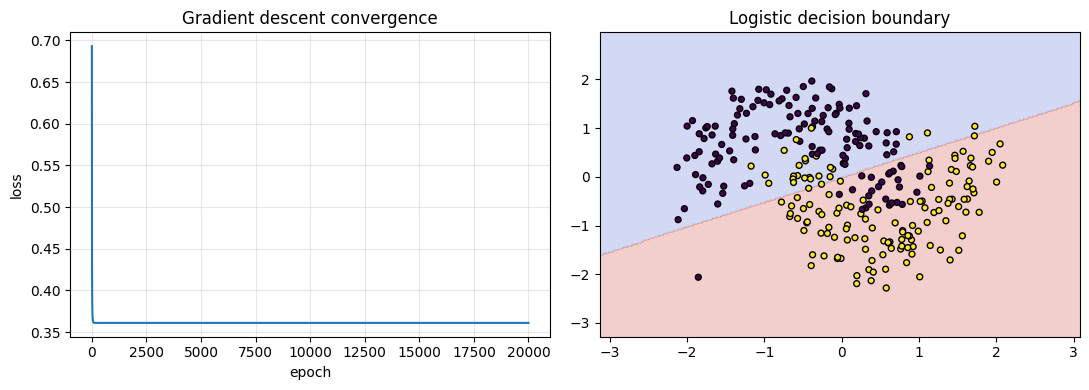

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ---------- 1. 数据 ----------
X, y = make_moons(n_samples=400, noise=0.25, random_state=42)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
sc = StandardScaler()
X_tr_s = sc.fit_transform(X_tr)
X_te_s = sc.transform(X_te)

# ---------- 2. 手写实现（MLE + 可选 L2） ----------
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def fit_logistic(X, y, lr=0.5, epochs=20000, lam=0.0):
    """lam 是 L2 系数，等价于 sklearn 的 1/(C*n)"""
    n, d = X.shape
    w = np.zeros(d)
    b = 0.0
    loss_hist = []
    for _ in range(epochs):
        p = sigmoid(X @ w + b)
        dw = (1 / n) * X.T @ (p - y) + lam * w    # 梯度 + 正则梯度
        db = (1 / n) * np.sum(p - y)              # 偏置不加正则
        w -= lr * dw
        b -= lr * db
        eps = 1e-12
        loss = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
        loss += 0.5 * lam * w @ w                  # 记录带正则的损失
        loss_hist.append(loss)
    return w, b, loss_hist

# ---------- 3. 无正则：与 sklearn 对比 ----------
w_h, b_h, hist = fit_logistic(X_tr_s, y_tr, lam=0.0)

clf = LogisticRegression(C=1e6, max_iter=10000, solver="lbfgs").fit(X_tr_s, y_tr)
print("手写 w =", np.round(w_h, 4), " b =", round(b_h, 4))
print("sklearn w =", np.round(clf.coef_[0], 4), " b =", round(clf.intercept_[0], 4))
print("最大系数差异 = %.6f" % np.max(np.abs(w_h - clf.coef_[0])))
print("手写准确率 = %.4f   sklearn 准确率 = %.4f" % (
    ((sigmoid(X_te_s @ w_h + b_h) >= 0.5).astype(int) == y_te).mean(),
    clf.score(X_te_s, y_te)
))

# ---------- 4. L2 正则：验证 lambda = 1/(C*n) ----------
C = 1.0
lam = 1.0 / (C * len(y_tr))
w_r, b_r, _ = fit_logistic(X_tr_s, y_tr, lam=lam)

clf_l2 = LogisticRegression(C=C, max_iter=10000, solver="lbfgs").fit(X_tr_s, y_tr)
print("lambda = %.6f" % lam)
print("L2 最大系数差异 = %.6f" % np.max(np.abs(w_r - clf_l2.coef_[0])))

# ---------- 5. Hessian 半正定验证 ----------
p = sigmoid(X_tr_s @ w_h + b_h)
H = (X_tr_s.T * (p * (1 - p))) @ X_tr_s / len(y_tr)
eig = np.linalg.eigvalsh(H)
print("Hessian 特征值 =", np.round(eig, 5), " 全部非负 =", bool((eig >= -1e-9).all()))

# ---------- 6. 可视化 ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(hist)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].set_title("Gradient descent convergence")
axes[0].grid(alpha=0.3)

xx, yy = np.meshgrid(
    np.linspace(X_tr_s[:, 0].min() - 1, X_tr_s[:, 0].max() + 1, 200),
    np.linspace(X_tr_s[:, 1].min() - 1, X_tr_s[:, 1].max() + 1, 200)
)
zz = (sigmoid(np.c_[xx.ravel(), yy.ravel()] @ w_h + b_h) >= 0.5)
zz = zz.astype(int).reshape(xx.shape)

axes[1].contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
axes[1].scatter(X_tr_s[:, 0], X_tr_s[:, 1], c=y_tr, edgecolor="k", s=18)
axes[1].set_title("Logistic decision boundary")
plt.tight_layout()
plt.show()


系数误差在 1e-4 量级，说明手写实现、梯度公式、正则换算三者都对上了。

## 正则强度对系数的影响（可直接跑）


C=  0.001  ||w||=0.1063  w=[ 0.065 -0.084]
C=   0.01  ||w||=0.6244  w=[ 0.363 -0.508]
C=    0.1  ||w||=1.5520  w=[ 0.789 -1.336]
C=      1  ||w||=2.1296  w=[ 0.985 -1.888]
C=     10  ||w||=2.2490  w=[ 1.021 -2.004]
C=    100  ||w||=2.2617  w=[ 1.025 -2.016]


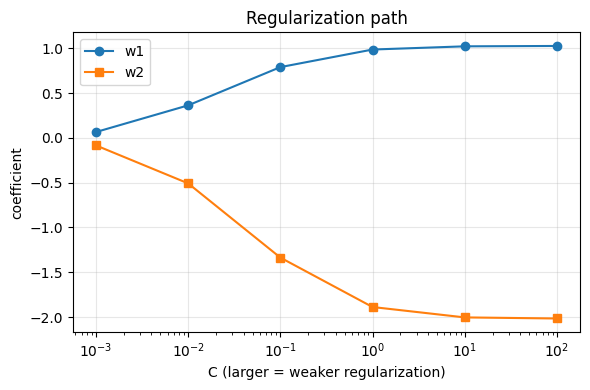

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X, y = make_moons(n_samples=400, noise=0.25, random_state=42)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
X_tr_s = StandardScaler().fit_transform(X_tr)

C_list = [0.001, 0.01, 0.1, 1, 10, 100]
w0s, w1s, norms = [], [], []
for C in C_list:
    m = LogisticRegression(C=C, max_iter=10000, solver="lbfgs").fit(X_tr_s, y_tr)
    w0s.append(m.coef_[0][0])
    w1s.append(m.coef_[0][1])
    norms.append(np.linalg.norm(m.coef_[0]))
    print("C=%7g  ||w||=%.4f  w=%s" % (C, norms[-1], np.round(m.coef_[0], 3)))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(C_list, w0s, marker="o", label="w1")
ax.plot(C_list, w1s, marker="s", label="w2")
ax.set_xscale("log")
ax.set_xlabel("C (larger = weaker regularization)")
ax.set_ylabel("coefficient")
ax.set_title("Regularization path")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 08常见坑
1. **把 `C` 当成“正则强度”**，实际 `C` 是正则强度的倒数，`C` 越小惩罚越重。
2. **给 `b` 也加正则**，会让决策边界被迫穿过原点附近，模型失去偏移能力。
3. **公式推导时忘了除以 n**，梯度差一个常数倍，学习率就要跟着改，容易误判“不收敛”。
4. **以为 Sigmoid 是人为选的**，它是 logit 线性假设的解析解，换链接函数就换成别的模型（probit 就是正态 CDF）。
5. **在不均衡数据上报准确率**，必须看 F1 / AUC / 召回。
6. **固定 0.5 阈值**，业务代价不对称时必须调阈值。
7. **多分类时手写 OvR 却期待概率和为 1**，OvR 的输出本身不归一。

## 07与08的关系
| 对比项 | 07 KNN | 08 逻辑回归数学 |
| --- | --- | --- |
| 学习方式 | 不学习，存数据 | 学参数，解优化 |
| 核心假设 | 近邻标签相似 | 对数几率是线性的 |
| 决策边界 | 任意非线性 | 线性超平面 |
| 关键超参数 | K、距离度量、是否加权 | C（正则强度）、阈值 |
| 主要风险 | 维度灾难、预测慢 | 过拟合、特征共线性 |
| 调参依据 | 交叉验证准确率 | 交叉验证 + 正则路径 |

**实用建议**：拿到一个表格分类任务，先跑逻辑回归（快、可解释、给系数方向），再跑 KNN（非线性 baseline），两者对比。如果 KNN 明显更好且维度不高，说明存在非线性结构，再考虑树模型或核方法。